<a href="https://colab.research.google.com/github/tofighi/tutorials/blob/master/AI/Performance_Metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Performance Metrics in Machine Learning: Classification, Regression, and Clustering

Welcome to the comprehensive module on **Machine Learning Performance Metrics**. In machine learning, training an algorithm is only half the battle; knowing how to properly evaluate, validate, and compare models is what separates robust real-world AI systems from catastrophic failures. A model that achieves "99% accuracy" might be completely useless, while a model with lower accuracy might save thousands of lives or millions of dollars.

This notebook provides a thorough pedagogical breakdown of performance evaluation across three core machine learning paradigms:

* **Part 1: Classification Performance Metrics & Decision Guide** — The confusion matrix, mathematical formulations of Accuracy, Precision, Recall, Specificity, False Positive Rate, and the F1 Score (with harmonic mean rationale). Deep-dive into why accuracy fails on imbalanced data (the Accuracy Paradox) and asymmetric error costs, ending with a metric comparison table and use-case guide.
* **Part 2: Step-by-Step Classification Worked Example & ROC/AUC** — A 5-record dataset calculated by hand and step-by-step for all metrics, decision threshold tuning, and a simplified intuitive derivation of the ROC curve and AUC (connecting trapezoidal area to Wilcoxon rank-sum concordance).
* **Part 3: Regression Performance Metrics** — Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the Coefficient of Determination ($R^2$). Explanation of negative $R^2$, outlier sensitivity ($L_1$ vs. $L_2$), and a step-by-step worked 5-point numerical example.
* **Part 4: Clustering Performance Metrics** — Evaluating unsupervised learning: Inertia / Within-Cluster Sum of Squares (WCSS), Silhouette Coefficient ($a(i)$ and $b(i)$), Davies-Bouldin Index (DBI), Calinski-Harabasz Index (CH), and external validation. Complete manual step-by-step calculation on a 4-point dataset.
* **Part 5: Practical Python Implementations & Visualizations** — Clean, production-grade Scikit-Learn implementations, annotated confusion matrix heatmaps, exact step-function ROC curves, threshold trade-off plots, regression residual diagnostics, and multi-metric K-means evaluation on 2D synthetic blobs.
* **Part 6: Master Summary & Decision Cheat Sheet** — A unified quick-reference guide for selecting the right metric for your problem.

---

## Table of Contents
1. **[Part 1: Classification Performance Metrics & Decision Guide](#part_1)**
   * [1.1 The Confusion Matrix: The Foundation](#section_1_1)
   * [1.2 Core Formulas & Theoretical Intuitions](#section_1_2)
   * [1.3 Why Accuracy Is Not Always the Best Metric](#section_1_3)
   * [1.4 When to Use Each Metric: Practical Decision Guide & Real-World Scenarios](#section_1_4)
   * [1.5 Comprehensive Classification Metrics Comparison Table](#section_1_5)
2. **[Part 2: Step-by-Step Classification Worked Example & ROC/AUC](#part_2)**
   * [2.1 The 5-Record Dataset](#section_2_1)
   * [2.2 Manual Step-by-Step Metric Calculations](#section_2_2)
   * [2.3 Threshold Analysis on the 5 Records](#section_2_3)
   * [2.4 Simplified Examples of ROC Curve and AUC](#section_2_4)
3. **[Part 3: Regression Performance Metrics](#part_3)**
   * [3.1 Regression Errors and Residuals](#section_3_1)
   * [3.2 Mean Absolute Error (MAE)](#section_3_2)
   * [3.3 Mean Squared Error (MSE) and Root Mean Squared Error (RMSE)](#section_3_3)
   * [3.4 Coefficient of Determination ($R^2$ Score) & Negative $R^2$](#section_3_4)
   * [3.5 Regression Metrics Comparison Table](#section_3_5)
   * [3.6 Step-by-Step Regression Worked Example (5 Points)](#section_3_6)
4. **[Part 4: Clustering Performance Metrics](#part_4)**
   * [4.1 The Challenge of Evaluating Unsupervised Learning](#section_4_1)
   * [4.2 Key Clustering Metrics: Inertia, Silhouette, Davies-Bouldin, Calinski-Harabasz](#section_4_2)
   * [4.3 Step-by-Step Clustering Worked Example (4 Points)](#section_4_3)
5. **[Part 5: Practical Python Implementations & Visualizations](#part_5)**
   * [5.1 Classification Metrics Code (5-Record Dataset)](#section_5_1)
   * [5.2 Classification Visualizations: Confusion Matrix, ROC-AUC, and Threshold Curves](#section_5_2)
   * [5.3 Regression Metrics Code & Outlier Sensitivity](#section_5_3)
   * [5.4 Regression Visualizations: Actual vs. Fitted and Residuals](#section_5_4)
   * [5.5 Clustering Metrics Code (Toy Dataset Verification)](#section_5_5)
   * [5.6 Realistic Clustering Experiment: K-Means Multi-Metric Analysis](#section_5_6)
6. **[Part 6: Master Summary & Decision Cheat Sheet](#part_6)**
7. **[Copyright Notice](#copyright_section)**


<a name="part_1"></a>
# Part 1: Classification Performance Metrics & Decision Guide

In binary classification, an algorithm assigns each observation to one of two mutually exclusive classes: **Positive (1)** or **Negative (0)**. To evaluate how well our model performs, we compare its predicted classes against the actual ground-truth classes.

---

<a name="section_1_1"></a>
### 1.1 The Confusion Matrix: The Foundation

The **Confusion Matrix** is a 2×2 contingency table that cross-tabulates actual ground truth against model predictions. All standard binary classification metrics are derived directly from the four counts inside this matrix:

| | **Predicted Positive ($\hat{y} = 1$)** | **Predicted Negative ($\hat{y} = 0$)** | **Total Actual** |
|:---|:---:|:---:|:---:|
| **Actual Positive ($y = 1$)** | **True Positive (TP)**<br>*(Correct hit)* | **False Negative (FN)**<br>*(Type II Error / Miss)* | **Actual Positives ($P = TP + FN$)** |
| **Actual Negative ($y = 0$)** | **False Positive (FP)**<br>*(Type I Error / False Alarm)* | **True Negative (TN)**<br>*(Correct rejection)* | **Actual Negatives ($N = TN + FP$)** |
| **Total Predicted** | **Predicted Positives ($P^* = TP + FP$)** | **Predicted Negatives ($N^* = TN + FN$)** | **Total Samples ($m = TP + TN + FP + FN$)** |

#### The Four Quadrants Defined:
1. **True Positive ($TP$):** The instance was truly positive, and the model correctly predicted positive.
   * *Example:* A patient has the disease, and the test correctly flags positive.
2. **True Negative ($TN$):** The instance was truly negative, and the model correctly predicted negative.
   * *Example:* A healthy patient is correctly diagnosed as disease-free.
3. **False Positive ($FP$) — Type I Error:** The instance was negative, but the model incorrectly predicted positive (*False Alarm*).
   * *Example:* A healthy patient is erroneously told they have a disease.
4. **False Negative ($FN$) — Type II Error:** The instance was positive, but the model incorrectly predicted negative (*Missed Case*).
   * *Example:* A sick patient is erroneously told they are healthy and sent home without treatment.


<a name="section_1_2"></a>
### 1.2 Core Formulas & Theoretical Intuitions

From the four fundamental quadrants ($TP, FP, TN, FN$), we derive the standard evaluation metrics.

---

#### 1. Accuracy
Accuracy measures the proportion of total predictions that were correct (both positive and negative):

$$\boxed{\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{\text{Number of Correct Predictions}}{\text{Total Number of Predictions}}} \tag{1.1}$$

* **Range:** $[0.0, 1.0]$ or $[0\%, 100\%]$.
* **Intuition:** "What fraction of the time was the model right across all classes?"

---

#### 2. Precision (Positive Predictive Value — PPV)
Precision answers the question: *Of all instances the model labeled as Positive, how many were actually Positive?*

$$\boxed{\text{Precision} = \frac{TP}{TP + FP} = \frac{\text{True Positives}}{\text{Total Predicted Positives}}} \tag{1.2}$$

* **Range:** $[0.0, 1.0]$.
* **Focus:** Minimizing **False Positives ($FP$)**. A high precision means when the model says "Yes", you can trust it.

---

#### 3. Recall (Sensitivity / True Positive Rate — TPR)
Recall answers the question: *Of all instances that were actually Positive, how many did the model successfully find?*

$$\boxed{\text{Recall} = \frac{TP}{TP + FN} = \frac{\text{True Positives}}{\text{Total Actual Positives}}} \tag{1.3}$$

* **Range:** $[0.0, 1.0]$.
* **Focus:** Minimizing **False Negatives ($FN$)**. A high recall means the model misses very few positive instances.

---

#### 4. Specificity (True Negative Rate — TNR)
Specificity measures the model's ability to correctly identify actual Negatives:

$$\boxed{\text{Specificity} = \frac{TN}{TN + FP} = \frac{\text{True Negatives}}{\text{Total Actual Negatives}}} \tag{1.4}$$

* **Range:** $[0.0, 1.0]$.
* **Focus:** Rejection of true negatives without sounding false alarms.

---

#### 5. False Positive Rate (FPR / Fall-out)
The False Positive Rate measures the proportion of actual Negatives that were mistakenly flagged as Positive:

$$\boxed{\text{FPR} = 1 - \text{Specificity} = \frac{FP}{FP + TN}} \tag{1.5}$$

* **Range:** $[0.0, 1.0]$ (Lower is better; 0 is ideal).
* **Role:** Serves as the $x$-axis in the Receiver Operating Characteristic (ROC) curve.

---

#### 6. F1 Score (Harmonic Mean of Precision and Recall)
The F1 score is the single-number balance between Precision and Recall:

$$\boxed{\text{F1 Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}} \tag{1.6}$$

> [!IMPORTANT]
> **Why the Harmonic Mean instead of the Arithmetic Mean?**
> The arithmetic mean of two numbers $a$ and $b$ is $\frac{a + b}{2}$. If we used the arithmetic mean:
> * Suppose a model predicts Positive for **every single sample**. It achieves $\text{Recall} = 1.0$ (100%), but due to endless false alarms, its $\text{Precision} = 0.02$ (2%).
> * **Arithmetic Mean:** $\frac{1.0 + 0.02}{2} = 0.51$ (51%) — a deceptively respectable score for a completely broken model!
> * **Harmonic Mean (F1):**
>   $$\text{F1} = 2 \times \frac{1.0 \times 0.02}{1.0 + 0.02} = \frac{0.04}{1.02} \approx 0.0392 \; (3.92\%)$$
> The harmonic mean strictly penalizes extreme disparity between Precision and Recall. It is close to the minimum of the two values; if *either* precision or recall collapses toward zero, the F1 score collapses toward zero.


<a name="section_1_3"></a>
### 1.3 Why Accuracy Is Not Always the Best Metric

In everyday conversation, "accuracy" sounds like the ultimate benchmark of quality. In machine learning, however, relying solely on accuracy can be dangerously misleading due to two fundamental factors: **Class Imbalance** and **Asymmetric Error Costs**.

---

#### 1. The Accuracy Paradox (Severe Class Imbalance)
Consider a rare disease screening model evaluating $1,000$ patients:
* **Actual Condition:** $990$ patients are healthy ($y=0$), and $10$ patients have the disease ($y=1$).
* Suppose a "dummy" model predicts $\hat{y} = 0$ (Healthy) for **every single patient** without even looking at their symptoms.

Let us evaluate this dummy model:
* $TP = 0$
* $TN = 990$
* $FP = 0$
* $FN = 10$

$$\text{Accuracy} = \frac{0 + 990}{1000} = \frac{990}{1000} = 99.0\%$$

$$\text{Recall} = \frac{TP}{TP + FN} = \frac{0}{0 + 10} = 0.0\%$$

$$\text{Precision} = \frac{TP}{TP + FP} = \frac{0}{0 + 0} = \text{Undefined / 0}$$

$$\text{F1 Score} = 0.0$$

> [!WARNING]
> **The Accuracy Paradox:** The model achieves a stellar **$99.0\%$ accuracy**, yet it failed to identify a single sick patient! If deployed in a clinic, all $10$ sick patients would leave untreated. Accuracy measures how well the model predicts the majority class, masking complete failure on the minority class.

---

#### 2. Asymmetric Costs of Errors
In the real world, **a False Positive and a False Negative are rarely equal in cost**:

* **Medical Diagnosis:**
  * *False Negative ($FN$):* A patient with malignant cancer is told they are healthy $\rightarrow$ **Death / Incurable progression** (Catastrophic cost).
  * *False Positive ($FP$):* A healthy patient receives a suspicious test $\rightarrow$ Follow-up biopsy clarifies health (Moderate financial/emotional cost).
  * *Conclusion:* We must optimize for **Recall** to eliminate $FN$, accepting a few $FP$ as an acceptable trade-off.

* **Email Spam Filtering:**
  * *False Positive ($FP$):* An urgent job offer or family emergency email is dumped into Spam $\rightarrow$ **Missed opportunity / Disastrous loss**.
  * *False Negative ($FN$):* A spam email slips into the Primary Inbox $\rightarrow$ Minor annoyance (user simply clicks delete).
  * *Conclusion:* We must optimize for **Precision** to eliminate $FP$, accepting occasional spam in the inbox.

* **Legal Justice System ("Blackstone's Ratio"):**
  * *"It is better that ten guilty persons escape than that one innocent suffer."*
  * *False Positive ($FP$):* Incarcerating an innocent person (Unacceptable violation of human rights).
  * *False Negative ($FN$):* A guilty person is acquitted.
  * *Conclusion:* Requires near-$100\%$ **Precision** ("beyond a reasonable doubt").

Accuracy treats a $\$100,000$ medical malpractice error and a $\$0.50$ spam deletion error with the exact same weight ($1.0$). Therefore, accuracy is an inadequate metric whenever class distributions are skewed or error consequences are unequal.


<a name="section_1_4"></a>
### 1.4 When to Use Each Metric: Practical Decision Guide & Real-World Scenarios

Selecting the appropriate metric depends directly on your problem domain, data balance, and operational objectives:

```
                            What is your primary concern?
                                          │
       ┌──────────────────────────────────┼─────────────────────────────────┐
       ▼                                  ▼                                 ▼
Cost of MISSING                   Cost of FALSE                     Balanced classes
positives is high                 ALARMS is high                    & equal error costs
 (FN is fatal)                     (FP is intolerable)                      │
       │                                  │                                 ▼
       ▼                                  ▼                             ACCURACY
    RECALL                            PRECISION
(e.g., Cancer,                    (e.g., Spam filter,
 Fraud, Intrusion)                 Courtroom verdict)
       │                                  │
       └────────────────┬─────────────────┘
                        ▼
           Need to balance both on
             imbalanced dataset?
                        │
                        ▼
                     F1 SCORE
            (or F_beta for weighted)
```

---

#### Detailed Scenarios by Metric:

1. **Use Accuracy when:**
   * The dataset is **well-balanced** (e.g., roughly $50\% / 50\%$ distribution between classes).
   * The costs of a False Positive and a False Negative are **symmetric and equal**.
   * *Real-world example:* Optical Character Recognition (OCR) for handwritten digits ($0$ through $9$ with roughly equal frequency).

2. **Use Precision when:**
   * You need to be **exceptionally confident** whenever the model predicts the positive class.
   * A **False Positive is expensive, embarrassing, or irreversible**.
   * *Real-world examples:*
     * **Automated Content Moderation / Account Ban:** Banning an innocent user's verified business account falsely disrupts livelihoods.
     * **Video Recommendation Engine:** Recommending irrelevant or offensive videos annoys the user and causes churn.
     * **Drug Discovery Candidate Selection:** Synthesizing molecules in a wet lab costs $\$200,000$ per test; false positives waste millions of dollars.

3. **Use Recall (Sensitivity) when:**
   * You cannot afford to **miss a single positive instance**.
   * A **False Negative is catastrophic, life-threatening, or expensive**.
   * *Real-world examples:*
     * **Oncology / Radiology Screening:** Missing a tumor at Stage 1 leads to fatal Stage 4 progression.
     * **Credit Card Fraud Detection:** Missing a fraudulent $\$10,000$ wire transfer costs the bank directly.
     * **Airport Security / Gun Detection:** Missing a weapon in an X-ray scanner poses immediate danger.

4. **Use F1 Score when:**
   * The classes are **imbalanced** (e.g., $95\%$ negative, $5\%$ positive).
   * You seek a **healthy operational compromise** between precision and recall, ensuring neither metric collapses.
   * *Real-world examples:*
     * **Search Engine Relevance:** You want relevant documents (Precision) without omitting key sources (Recall).
     * **Customer Churn Prediction:** Targeting at-risk customers with discount retention offers.

5. **Use ROC-AUC when:**
   * You want to evaluate the **overall ranking capability** of the model independent of any single arbitrary decision threshold ($\tau$).
   * You plan to tune the classification threshold later based on business constraints.
   * *Real-world examples:*
     * **Credit Risk Scoring:** The model produces a credit score from $0$ to $850$; the bank can adjust the approval threshold dynamically depending on quarterly liquidity.


<a name="section_1_5"></a>
### 1.5 Comprehensive Classification Metrics Comparison Table

The following master table contrasts all key classification metrics, their algebraic formulas, strategic focus, failure modes, and industry applications:

| Metric | Formula | Key Question Answered | Best Used When... | Major Pitfall / Vulnerability | Real-World Example |
|:---|:---:|:---|:---|:---|:---|
| **Accuracy** | $\frac{TP + TN}{TP + TN + FP + FN}$ | *What fraction of all predictions was correct?* | Classes are balanced and error costs are equal | Deceptive on imbalanced data (**Accuracy Paradox**) | Handwritten digit classification (MNIST) |
| **Precision** | $\frac{TP}{TP + FP}$ | *When the model predicts Positive, how often is it right?* | False Positives ($FP$) carry severe penalties | Ignores missed positives ($FN$ can be very high) | Email spam filter; felony sentencing |
| **Recall (Sensitivity)** | $\frac{TP}{TP + FN}$ | *Out of all actual Positives, how many were caught?* | False Negatives ($FN$) are dangerous or fatal | Ignores false alarms ($FP$ can be very high) | Early cancer diagnosis; financial fraud |
| **Specificity** | $\frac{TN}{TN + FP}$ | *Out of all actual Negatives, how many were cleared?* | Confirming health / innocence of negative cases | Irrelevant to positive class detection | Pre-employment background checks |
| **False Positive Rate** | $\frac{FP}{FP + TN} = 1 - \text{Spec}$ | *What fraction of innocent/negative cases was falsely accused?* | Minimizing false alarm rate | Decreases if $TN$ explodes, masking issues | Intrusion detection alarm systems |
| **F1 Score** | $2 \cdot \frac{\text{Prec} \cdot \text{Rec}}{\text{Prec} + \text{Rec}}$ | *What is the harmonic balance between Precision and Recall?* | Data is imbalanced; both $FP$ and $FN$ matter | Gives equal weight to Precision and Recall | Customer churn prediction; search retrieval |
| **ROC-AUC** | $\int_0^1 \text{TPR}(f) \, df$ | *How well does the model rank positives above negatives?* | Evaluating threshold-free discrimination power | Can be overly optimistic under extreme imbalance | Credit risk scoring; bio-assay screening |


<a name="part_2"></a>
# Part 2: Step-by-Step Classification Worked Example & ROC/AUC

To cement theoretical understanding, let us work through a complete numerical example with a concrete **5-record dataset**. We will calculate every metric by hand, examine the effect of changing decision thresholds, and construct an intuitive step-by-step ROC curve and AUC calculation.

---

<a name="section_2_1"></a>
### 2.1 The 5-Record Dataset

Consider a diagnostic test applied to $5$ patients. The model outputs a predicted continuous probability $\hat{p} \in [0, 1]$ of having the disease. We apply the standard decision threshold $\tau = 0.50$ (where $\hat{y} = 1$ if $\hat{p} \ge 0.50$, else $\hat{y} = 0$).

| Patient ID ($i$) | Actual Disease ($y$) | Predicted Probability ($\hat{p}$) | Binary Prediction ($\hat{y}$, $\tau=0.50$) | Classification Category |
|:---:|:---:|:---:|:---:|:---:|
| **1** | **$1$ (Sick)** | $0.92$ | **$1$ (Positive)** | **True Positive (TP)** |
| **2** | **$1$ (Sick)** | $0.78$ | **$1$ (Positive)** | **True Positive (TP)** |
| **3** | **$0$ (Healthy)** | $0.65$ | **$1$ (Positive)** | **False Positive (FP)** *(False Alarm)* |
| **4** | **$1$ (Sick)** | $0.38$ | **$0$ (Negative)** | **False Negative (FN)** *(Missed Case)* |
| **5** | **$0$ (Healthy)** | $0.15$ | **$0$ (Negative)** | **True Negative (TN)** |

#### Confusion Matrix Counts:
* **True Positives ($TP$):** $2$ (Patients 1 and 2)
* **False Positives ($FP$):** $1$ (Patient 3)
* **True Negatives ($TN$):** $1$ (Patient 5)
* **False Negatives ($FN$):** $1$ (Patient 4)
* **Total Actual Positives ($P = TP + FN$):** $2 + 1 = 3$
* **Total Actual Negatives ($N = TN + FP$):** $1 + 1 = 2$
* **Total Instances ($m$):** $5$


<a name="section_2_2"></a>
### 2.2 Manual Step-by-Step Metric Calculations (at $\tau = 0.50$)

Now, let us calculate every metric using the counts from our 5-record dataset:

#### 1. Accuracy (Eq. 1.1)
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{2 + 1}{2 + 1 + 1 + 1} = \frac{3}{5} = \mathbf{0.60} \quad (60.0\%)$$

*Interpretation:* The model made the correct diagnosis for 3 out of the 5 patients.

---

#### 2. Precision (Eq. 1.2)
$$\text{Precision} = \frac{TP}{TP + FP} = \frac{2}{2 + 1} = \frac{2}{3} \approx \mathbf{0.6667} \quad (66.67\%)$$

*Interpretation:* When the model predicted a patient was sick (Patients 1, 2, and 3), it was correct 2 out of 3 times ($66.7\%$). Patient 3 was a false alarm.

---

#### 3. Recall / Sensitivity (Eq. 1.3)
$$\text{Recall} = \frac{TP}{TP + FN} = \frac{2}{2 + 1} = \frac{2}{3} \approx \mathbf{0.6667} \quad (66.67\%)$$

*Interpretation:* Out of the 3 truly sick patients (Patients 1, 2, and 4), the model successfully identified 2 of them ($66.7\%$). Patient 4 was missed.

---

#### 4. Specificity / True Negative Rate (Eq. 1.4)
$$\text{Specificity} = \frac{TN}{TN + FP} = \frac{1}{1 + 1} = \frac{1}{2} = \mathbf{0.50} \quad (50.0\%)$$

*Interpretation:* Out of the 2 healthy patients (Patients 3 and 5), the model correctly identified 1 as healthy.

---

#### 5. False Positive Rate (Eq. 1.5)
$$\text{FPR} = 1 - \text{Specificity} = 1 - 0.50 = \mathbf{0.50} \quad (50.0\%) \quad \left( \text{or } \frac{FP}{FP + TN} = \frac{1}{1 + 1} = 0.50 \right)$$

*Interpretation:* $50\%$ of healthy patients were mistakenly flagged as sick.

---

#### 6. F1 Score (Eq. 1.6)
$$\text{F1 Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} = 2 \times \frac{\frac{2}{3} \times \frac{2}{3}}{\frac{2}{3} + \frac{2}{3}} = 2 \times \frac{\frac{4}{9}}{\frac{4}{3}} = 2 \times \frac{4}{9} \times \frac{3}{4} = \frac{2}{3} \approx \mathbf{0.6667} \quad (66.67\%)$$

*Verification via quadrant formula:*
$$\text{F1} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN} = \frac{2(2)}{2(2) + 1 + 1} = \frac{4}{4 + 2} = \frac{4}{6} = \frac{2}{3} \approx \mathbf{0.6667}$$


<a name="section_2_3"></a>
### 2.3 Threshold Analysis on the 5 Records

The decision threshold $\tau = 0.50$ is not set in stone; it is an adjustable control knob. By shifting $\tau$, we trade precision for recall:

#### Case A: Conservative Threshold ($\tau = 0.70$) — High Precision Focus
Only classify as Positive if $\hat{p} \ge 0.70$:
* Predictions: Patient 1 ($0.92 \ge 0.70 \rightarrow 1$), Patient 2 ($0.78 \ge 0.70 \rightarrow 1$), Patients 3, 4, 5 $\rightarrow 0$.
* **Counts:** $TP = 2$, $FP = 0$, $FN = 1$, $TN = 2$.
* **Precision:** $\frac{2}{2 + 0} = \mathbf{1.00} \; (100\%)$ — *Zero false alarms!*
* **Recall:** $\frac{2}{2 + 1} = \frac{2}{3} \approx \mathbf{0.6667} \; (66.7\%)$.
* **Accuracy:** $\frac{2 + 2}{5} = \mathbf{0.80} \; (80.0\%)$.
* **F1 Score:** $2 \times \frac{1.0 \times (2/3)}{1.0 + (2/3)} = \frac{4/3}{5/3} = \mathbf{0.80} \; (80.0\%)$.

---

#### Case B: Aggressive Threshold ($\tau = 0.30$) — High Recall Focus
Classify as Positive if $\hat{p} \ge 0.30$ (catch every possible sick patient):
* Predictions: Patients 1, 2, 3, 4 $\rightarrow 1$ (all $\ge 0.30$), Patient 5 $\rightarrow 0$.
* **Counts:** $TP = 3$, $FP = 1$, $FN = 0$, $TN = 1$.
* **Recall:** $\frac{3}{3 + 0} = \mathbf{1.00} \; (100\%)$ — *Zero missed cases!*
* **Precision:** $\frac{3}{3 + 1} = \frac{3}{4} = \mathbf{0.75} \; (75.0\%)$.
* **Accuracy:** $\frac{3 + 1}{5} = \mathbf{0.80} \; (80.0\%)$.
* **F1 Score:** $2 \times \frac{0.75 \times 1.0}{0.75 + 1.0} = \frac{1.50}{1.75} = \frac{6}{7} \approx \mathbf{0.8571} \; (85.7\%)$.

> [!TIP]
> **Takeaway:** Notice how lowering the threshold from $0.70$ to $0.30$ increased Recall from $66.7\%$ to $100\%$ by accepting 1 False Positive. In a clinical cancer screening context, $\tau = 0.30$ is vastly superior because it achieves $100\%$ recall without excessive false alarms.


<a name="section_2_4"></a>
### 2.4 Simplified Examples of ROC Curve and AUC

The **ROC Curve (Receiver Operating Characteristic)** evaluates a model across **all possible classification thresholds** simultaneously.

* **$y$-axis:** True Positive Rate ($\text{TPR} = \text{Recall} = \frac{TP}{P}$)
* **$x$-axis:** False Positive Rate ($\text{FPR} = 1 - \text{Specificity} = \frac{FP}{N}$)
* **AUC (Area Under the ROC Curve):** A scalar value between $0.0$ and $1.0$:
  * $\text{AUC} = 1.0$: Perfect classification (all positives ranked above all negatives).
  * $\text{AUC} = 0.5$: Worthless classifier (performs identically to random coin tossing).
  * $\text{AUC} < 0.5$: Worse than random (predictions are inverted).

---

#### Manual Derivation of ROC Operating Points on the 5-Record Dataset
Sort the 5 instances in descending order of their predicted probability $\hat{p}$:

1. Patient 1: $\hat{p} = 0.92$, Actual $y = 1$ (Positive)
2. Patient 2: $\hat{p} = 0.78$, Actual $y = 1$ (Positive)
3. Patient 3: $\hat{p} = 0.65$, Actual $y = 0$ (Negative)
4. Patient 4: $\hat{p} = 0.38$, Actual $y = 1$ (Positive)
5. Patient 5: $\hat{p} = 0.15$, Actual $y = 0$ (Negative)

Total Positives $P = 3$, Total Negatives $N = 2$.

Now, let threshold $\tau$ sweep from $+\infty$ down to $-\infty$:

| Operating Threshold Cutoff | Predicted Positives | TP | FP | $\text{FPR} = \frac{FP}{2}$ | $\text{TPR} = \frac{TP}{3}$ | ROC Coordinate $(x, y)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **$\tau > 0.92$** (e.g., $1.00$) | None | $0$ | $0$ | $0.00$ | $0.00$ | $(0.00, 0.00)$ |
| **$0.78 < \tau \le 0.92$** (e.g., $0.85$) | {1} | $1$ | $0$ | $0.00$ | $1/3 \approx 0.333$ | $(0.00, 0.333)$ |
| **$0.65 < \tau \le 0.78$** (e.g., $0.70$) | {1, 2} | $2$ | $0$ | $0.00$ | $2/3 \approx 0.667$ | $(0.00, 0.667)$ |
| **$0.38 < \tau \le 0.65$** (e.g., $0.50$) | {1, 2, 3} | $2$ | $1$ | $1/2 = 0.50$ | $2/3 \approx 0.667$ | $(0.50, 0.667)$ |
| **$0.15 < \tau \le 0.38$** (e.g., $0.25$) | {1, 2, 3, 4} | $3$ | $1$ | $1/2 = 0.50$ | $3/3 = 1.000$ | $(0.50, 1.000)$ |
| **$\tau \le 0.15$** (e.g., $0.00$) | {1, 2, 3, 4, 5} | $3$ | $2$ | $2/2 = 1.00$ | $3/3 = 1.000$ | $(1.00, 1.000)$ |

---

#### Step-by-Step AUC Calculation (Trapezoidal Rule)
The ROC curve is a step function bounded by the coordinates above:
* From $\text{FPR} = 0.0$ to $\text{FPR} = 0.50$: The curve steps up to $\text{TPR} = 2/3$. The rectangular area under this segment is:
  $$\text{Area}_1 = \Delta \text{FPR} \times \text{TPR} = (0.50 - 0.00) \times \frac{2}{3} = \frac{1}{2} \times \frac{2}{3} = \frac{1}{3} \approx 0.3333$$
* From $\text{FPR} = 0.50$ to $\text{FPR} = 1.00$: The curve steps up to $\text{TPR} = 1.00$. The rectangular area under this segment is:
  $$\text{Area}_2 = \Delta \text{FPR} \times \text{TPR} = (1.00 - 0.50) \times 1.00 = 0.50 = \frac{1}{2}$$

$$\boxed{\text{Total AUC} = \text{Area}_1 + \text{Area}_2 = \frac{1}{3} + \frac{1}{2} = \frac{5}{6} \approx \mathbf{0.8333}} \tag{2.1}$$

---

> [!NOTE]
> **Probabilistic Interpretation of AUC (Wilcoxon-Mann-Whitney Statistic):**
> Mathematically, **AUC equals the probability that a randomly chosen positive sample will be assigned a higher predicted probability than a randomly chosen negative sample**.
> Let us verify this directly by pairing every positive sample ($y=1$) against every negative sample ($y=0$):
> * Total possible pairs = $3 \text{ positives} \times 2 \text{ negatives} = 6 \text{ pairs}$.
>
> 1. Pair (Patient 1, Patient 3): $\hat{p}_1 = 0.92 > \hat{p}_3 = 0.65$ $\rightarrow$ **Concordant (1 pt)**
> 2. Pair (Patient 1, Patient 5): $\hat{p}_1 = 0.92 > \hat{p}_5 = 0.15$ $\rightarrow$ **Concordant (1 pt)**
> 3. Pair (Patient 2, Patient 3): $\hat{p}_2 = 0.78 > \hat{p}_3 = 0.65$ $\rightarrow$ **Concordant (1 pt)**
> 4. Pair (Patient 2, Patient 5): $\hat{p}_2 = 0.78 > \hat{p}_5 = 0.15$ $\rightarrow$ **Concordant (1 pt)**
> 5. Pair (Patient 4, Patient 3): $\hat{p}_4 = 0.38 < \hat{p}_3 = 0.65$ $\rightarrow$ **Discordant (0 pt)** *(The only error in ranking!)*
> 6. Pair (Patient 4, Patient 5): $\hat{p}_4 = 0.38 > \hat{p}_5 = 0.15$ $\rightarrow$ **Concordant (1 pt)**
>
> Total Concordant Pairs = $5$ out of $6$.
> $$\text{Concordance Probability} = \frac{5}{6} \approx \mathbf{0.8333}$$
> This proves exactly why the geometric trapezoidal area and the pairwise ranking probability are identical!


<a name="part_3"></a>
# Part 3: Regression Performance Metrics

In **regression**, the target variable $y \in \mathbb{R}$ is continuous (e.g., house prices, temperatures, stock values). We cannot build a confusion matrix of hits and misses because the probability of predicting the *exact* floating-point value is effectively zero. Instead, regression metrics evaluate the **magnitudes of the prediction errors (residuals)**.

---

<a name="section_3_1"></a>
### 3.1 Regression Errors and Residuals

For each sample $i$, the model produces a predicted value $\hat{y}_i$. The **residual** (error) is defined as:

$$e_i = y_i - \hat{y}_i \tag{3.1}$$

* If $e_i > 0$: The model **underpredicted** the true value.
* If $e_i < 0$: The model **overpredicted** the true value.
* If $e_i = 0$: The prediction was exact.


<a name="section_3_2"></a>
### 3.2 Mean Absolute Error (MAE)

The **Mean Absolute Error (MAE)** calculates the average magnitude of the errors without considering their sign ($L_1$ norm):

$$\boxed{\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i| = \frac{1}{n} \sum_{i=1}^n |e_i|} \tag{3.2}$$

* **Units:** Same units as the target variable $y$ (e.g., dollars, meters).
* **Robustness:** Highly **robust to outliers**. Because errors are not squared, an isolated huge error does not dominate the overall score.
* **Geometric interpretation:** The model minimizing MAE finds the **conditional median** of the target distribution.


<a name="section_3_3"></a>
### 3.3 Mean Squared Error (MSE) and Root Mean Squared Error (RMSE)

The **Mean Squared Error (MSE)** squares each residual before averaging ($L_2$ norm):

$$\boxed{\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2 = \frac{1}{n} \sum_{i=1}^n e_i^2} \tag{3.3}$$

* **Units:** Squared units of the target variable ($y^2$, e.g., $\text{dollars}^2$). This makes direct human interpretation difficult.

To restore the error metric to the original target units, we take the square root to obtain the **Root Mean Squared Error (RMSE)**:

$$\boxed{\text{RMSE} = \sqrt{\text{MSE}} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}} \tag{3.4}$$

* **Units:** Same units as the target variable $y$.
* **Sensitivity to Outliers:** Because the errors are squared, **RMSE heavily penalizes large errors**. For example, an error of $10$ adds $100$ to the sum, whereas an error of $2$ adds only $4$.
* **Geometric interpretation:** The model minimizing MSE/RMSE finds the **conditional mean** of the target distribution.

> [!IMPORTANT]
> **Relationship Between MAE and RMSE:**
> By the Cauchy-Schwarz inequality:
> $$\text{MAE} \le \text{RMSE} \le \sqrt{n} \cdot \text{MAE}$$
> * $\text{RMSE} = \text{MAE}$ only when all individual error magnitudes $|e_i|$ are identical.
> * The larger the gap between $\text{RMSE}$ and $\text{MAE}$, the greater the variance of individual errors (indicating the presence of large outliers).


<a name="section_3_4"></a>
### 3.4 Coefficient of Determination ($R^2$ Score) & Negative $R^2$

While MAE and RMSE depend on the scale of the target variable, the **Coefficient of Determination ($R^2$)** provides a scale-independent, normalized measure of explanatory power:

$$\boxed{R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}} = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}} \tag{3.5}$$

where $\bar{y} = \frac{1}{n} \sum_{i=1}^n y_i$ is the sample mean of the actual values, $SS_{\text{res}}$ is the **Residual Sum of Squares**, and $SS_{\text{tot}}$ is the **Total Sum of Squares** (proportional to target variance).

---

#### Interpreting $R^2$ Values:
* **$R^2 = 1.0$ (100%):** Perfect prediction ($SS_{\text{res}} = 0$). Every prediction lands exactly on the true value.
* **$R^2 = 0.0$ (0%):** The model performs no better than simply predicting the historical average $\bar{y}$ for every sample ($\hat{y}_i = \bar{y}$).
* **$0.0 < R^2 < 1.0$:** The fraction of total target variance explained by the model features. For example, $R^2 = 0.85$ means the model explains $85\%$ of the variability in the outcome.

> [!WARNING]
> **Can $R^2$ Be Negative? YES!**
> A common misconception is that $R^2$ must lie between $0$ and $1$. While $R^2$ is bounded between $0$ and $1$ on the training set for Ordinary Least Squares (OLS) with an intercept, **$R^2$ can be arbitrarily negative on test data or for non-linear models**.
> If $R^2 < 0$, it means $SS_{\text{res}} > SS_{\text{tot}}$ — the model's predictions are **worse than simply drawing a horizontal line at the mean $\bar{y}$**!

---

#### Adjusted $R^2$
Standard $R^2$ has a flaw: adding more features to a model will *always* increase (or maintain) $R^2$, even if the features are pure random noise. **Adjusted $R^2$** corrects for model complexity:

$$\boxed{R^2_{\text{adj}} = 1 - \left( \frac{1 - R^2}{n - p - 1} \right)(n - 1)} \tag{3.6}$$

where $n$ is sample size and $p$ is the number of predictors. $R^2_{\text{adj}}$ penalizes adding uninformative variables.


<a name="section_3_5"></a>
### 3.5 Regression Metrics Comparison Table

| Metric | Formula | Scale / Units | Sensitivity to Outliers | Optimization Target | Best Used When... |
|:---|:---:|:---:|:---:|:---:|:---|
| **MAE** | $\frac{1}{n}\sum |y_i - \hat{y}_i|$ | Same as target $y$ | **Low (Robust)** | Conditional Median | Data has extreme noise/outliers; linear penalty desired |
| **MSE** | $\frac{1}{n}\sum (y_i - \hat{y}_i)^2$ | Squared units $y^2$ | **Very High** | Conditional Mean | Mathematical derivation; loss function for gradient descent |
| **RMSE** | $\sqrt{\text{MSE}}$ | Same as target $y$ | **High** | Conditional Mean | Large errors are especially undesirable (e.g., flight delays) |
| **$R^2$** | $1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}}$ | Unitless ($(-\infty, 1]$) | **High** | Variance Explained | Comparing performance across different targets/datasets |
| **$R^2_{\text{adj}}$** | $1 - \frac{(1-R^2)(n-1)}{n-p-1}$ | Unitless ($(-\infty, 1]$) | **High** | Parsimonious Fit | Feature selection; comparing models with different feature counts |


<a name="section_3_6"></a>
### 3.6 Step-by-Step Regression Worked Example (5 Points)

Let us evaluate a regression model predicting home prices (in thousands of dollars) across $5$ properties:

| Property ID ($i$) | Actual Value ($y_i$) | Predicted Value ($\hat{y}_i$) | Residual ($e_i = y_i - \hat{y}_i$) | $|e_i|$ (Absolute Error) | $e_i^2$ (Squared Error) | $(y_i - \bar{y})^2$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **1** | $10.0$ | $12.0$ | $-2.0$ | $2.0$ | $4.0$ | $(10.0 - 20.0)^2 = 100.0$ |
| **2** | $20.0$ | $18.0$ | $+2.0$ | $2.0$ | $4.0$ | $(20.0 - 20.0)^2 = 0.0$ |
| **3** | $15.0$ | $16.0$ | $-1.0$ | $1.0$ | $1.0$ | $(15.0 - 20.0)^2 = 25.0$ |
| **4** | $30.0$ | $32.0$ | $-2.0$ | $2.0$ | $4.0$ | $(30.0 - 20.0)^2 = 100.0$ |
| **5** | $25.0$ | $22.0$ | $+3.0$ | $3.0$ | $9.0$ | $(25.0 - 20.0)^2 = 25.0$ |
| **Sum ($\Sigma$)** | $\mathbf{100.0}$ | $\mathbf{100.0}$ | $\mathbf{0.0}$ | $\mathbf{10.0}$ | $\mathbf{22.0}$ | $\mathbf{250.0}$ |

#### Summary Totals:
* Sample size: $n = 5$
* Mean of actual values: $\bar{y} = \frac{100.0}{5} = \mathbf{20.0}$
* Sum of Absolute Errors: $\sum |e_i| = 10.0$
* Residual Sum of Squares ($SS_{\text{res}}$): $\sum e_i^2 = 22.0$
* Total Sum of Squares ($SS_{\text{tot}}$): $\sum (y_i - \bar{y})^2 = 250.0$

---

#### Step-by-Step Metric Calculations:

1. **Mean Absolute Error (MAE):**
   $$\text{MAE} = \frac{\sum |e_i|}{n} = \frac{10.0}{5} = \mathbf{2.00}$$
   *Interpretation:* On average, predictions deviate from actual home values by $\$2,000$.

2. **Mean Squared Error (MSE):**
   $$\text{MSE} = \frac{\sum e_i^2}{n} = \frac{22.0}{5} = \mathbf{4.40}$$

3. **Root Mean Squared Error (RMSE):**
   $$\text{RMSE} = \sqrt{\text{MSE}} = \sqrt{4.40} \approx \mathbf{2.0976}$$
   *Interpretation:* Notice that $\text{RMSE} (2.098) > \text{MAE} (2.000)$ because the error of $3.0$ on property 5 is penalized more heavily.

4. **Coefficient of Determination ($R^2$):**
   $$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}} = 1 - \frac{22.0}{250.0} = 1 - 0.088 = \mathbf{0.9120} \quad (91.20\%)$$
   *Interpretation:* The regression model successfully explains **$91.2\%$** of the variance in property prices relative to a simple horizontal average line.


<a name="part_4"></a>
# Part 4: Clustering Performance Metrics

Clustering is an **unsupervised learning** paradigm: the algorithm groups unlabeled data points into clusters such that points within the same cluster are similar (**compactness / cohesion**) while points in different clusters are distinct (**separation**).

---

<a name="section_4_1"></a>
### 4.1 The Challenge of Evaluating Unsupervised Learning

Unlike supervised classification or regression, clustering algorithms rarely have ground-truth target labels ($y$) to compare against. Therefore, evaluation is divided into two broad categories:

1. **Internal Evaluation Metrics (Unsupervised):** Evaluate cluster geometry directly using the dataset features $X$. These quantify cluster cohesion and separation without requiring external labels.
   * *Examples:* Inertia (WCSS), Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index.
2. **External Evaluation Metrics (Supervised):** Used when ground-truth labels are available (e.g., in academic benchmark datasets).
   * *Examples:* Adjusted Rand Index (ARI), Normalized Mutual Information (NMI).


<a name="section_4_2"></a>
### 4.2 Key Clustering Metrics: Inertia, Silhouette, Davies-Bouldin, Calinski-Harabasz

Here are the four most important clustering metrics used in machine learning:

---

#### 1. Inertia / Within-Cluster Sum of Squares (WCSS)
Inertia measures how tightly packed the points in a cluster are around their centroid $\mu_k$:

$$\boxed{\text{WCSS} = \sum_{k=1}^K \sum_{x \in C_k} ||x - \mu_k||^2} \tag{4.1}$$

* **Goal:** **Lower is better**.
* **Limitation:** Inertia monotonically decreases as $K$ increases (if $K=n$, each point is its own centroid and $\text{WCSS} = 0$).
* **Usage (The Elbow Method):** We plot WCSS against $K$ and locate the "elbow point" — the inflection point where additional clusters yield diminishing returns.

---

#### 2. Silhouette Coefficient (Silhouette Score)
The Silhouette Coefficient evaluates both **cluster cohesion** (how close a point is to its own cluster) and **cluster separation** (how far it is from the nearest neighboring cluster).

For each individual sample $i$:
1. $a(i)$ = Mean distance from sample $i$ to all other points in the **same cluster**:
   $$a(i) = \frac{1}{|C_A| - 1} \sum_{j \in C_A, j \ne i} d(i, j)$$
2. $b(i)$ = Mean distance from sample $i$ to all points in the **nearest neighboring cluster**:
   $$b(i) = \min_{C_B \ne C_A} \left( \frac{1}{|C_B|} \sum_{j \in C_B} d(i, j) \right)$$

The silhouette coefficient for sample $i$ is defined as:

$$\boxed{s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}} \tag{4.2}$$

* **Range:** $[-1.0, +1.0]$.
  * **$s(i) \approx +1.0$:** Highly dense and well-separated cluster ($b(i) \gg a(i)$).
  * **$s(i) \approx 0.0$:** Sample lies on or near the decision boundary between two clusters.
  * **$s(i) < 0$:** Sample is closer to the neighboring cluster than its own ($a(i) > b(i)$) $\rightarrow$ **misclustered point**.
* **Global Dataset Score:** The average $\bar{s} = \frac{1}{n} \sum_{i=1}^n s(i)$. **Higher is better**.

---

#### 3. Davies-Bouldin Index (DBI)
The Davies-Bouldin Index measures the average similarity between each cluster and its most similar rival:

$$\boxed{DB = \frac{1}{K} \sum_{i=1}^K \max_{j \ne i} \left( \frac{s_i + s_j}{d(\mu_i, \mu_j)} \right)} \tag{4.3}$$

where $s_i$ is the average intra-cluster distance of points in cluster $i$ to its centroid $\mu_i$ (cluster dispersion), and $d(\mu_i, \mu_j)$ is the Euclidean distance between centroids $\mu_i$ and $\mu_j$.
* **Goal:** **Lower is better** (minimum theoretical value is $0$).
* **Intuition:** A lower index means clusters are compact ($s_i, s_j$ are small) and far apart ($d(\mu_i, \mu_j)$ is large).

---

#### 4. Calinski-Harabasz Index (Variance Ratio Criterion — CH)
The Calinski-Harabasz Index is the ratio of between-cluster dispersion to within-cluster dispersion:

$$\boxed{CH = \frac{\text{Tr}(B_K) / (K - 1)}{\text{Tr}(W_K) / (n - K)}} \tag{4.4}$$

where $B_K$ is the between-cluster scatter matrix and $W_K$ is the within-cluster scatter matrix.
* **Goal:** **Higher is better**.
* **Intuition:** Rewards models with large between-cluster variance (well separated) and small within-cluster variance (dense). Fast to compute.


<a name="section_4_3"></a>
### 4.3 Step-by-Step Clustering Worked Example (4 Points)

Let us calculate all internal clustering metrics by hand on a 1-dimensional toy dataset with $4$ points partitioned into $K = 2$ clusters:

* **Cluster 1 ($C_1$):** $x_1 = 1.0, \; x_2 = 2.0$
* **Cluster 2 ($C_2$):** $x_3 = 6.0, \; x_4 = 8.0$

---

#### 1. Centroids & Inertia (WCSS)
* Centroid 1: $\mu_1 = \frac{1.0 + 2.0}{2} = \mathbf{1.5}$
* Centroid 2: $\mu_2 = \frac{6.0 + 8.0}{2} = \mathbf{7.0}$

Within-cluster squared distances:
* Point 1: $(1.0 - 1.5)^2 = (-0.5)^2 = 0.25$
* Point 2: $(2.0 - 1.5)^2 = (+0.5)^2 = 0.25$
* Point 3: $(6.0 - 7.0)^2 = (-1.0)^2 = 1.00$
* Point 4: $(8.0 - 7.0)^2 = (+1.0)^2 = 1.00$

$$\boxed{\text{Inertia (WCSS)} = 0.25 + 0.25 + 1.00 + 1.00 = \mathbf{2.50}}$$

---

#### 2. Silhouette Coefficient for Each Point

* **For Point 1 ($x_1 = 1.0$):**
  * Same cluster ($C_1$): distance to $x_2$ is $|1.0 - 2.0| = 1.0 \rightarrow a(x_1) = 1.0$
  * Other cluster ($C_2$): distances to $x_3$ ($|1.0 - 6.0| = 5.0$) and $x_4$ ($|1.0 - 8.0| = 7.0$). Mean $b(x_1) = \frac{5.0 + 7.0}{2} = 6.0$
  * $$s(x_1) = \frac{b(x_1) - a(x_1)}{\max(a(x_1), b(x_1))} = \frac{6.0 - 1.0}{\max(1.0, 6.0)} = \frac{5.0}{6.0} \approx \mathbf{0.8333}$$

* **For Point 2 ($x_2 = 2.0$):**
  * Same cluster ($C_1$): distance to $x_1$ is $|2.0 - 1.0| = 1.0 \rightarrow a(x_2) = 1.0$
  * Other cluster ($C_2$): distances to $x_3$ ($|2.0 - 6.0| = 4.0$) and $x_4$ ($|2.0 - 8.0| = 6.0$). Mean $b(x_2) = \frac{4.0 + 6.0}{2} = 5.0$
  * $$s(x_2) = \frac{5.0 - 1.0}{\max(1.0, 5.0)} = \frac{4.0}{5.0} = \mathbf{0.8000}$$

* **For Point 3 ($x_3 = 6.0$):**
  * Same cluster ($C_2$): distance to $x_4$ is $|6.0 - 8.0| = 2.0 \rightarrow a(x_3) = 2.0$
  * Other cluster ($C_1$): distances to $x_1$ ($|6.0 - 1.0| = 5.0$) and $x_2$ ($|6.0 - 2.0| = 4.0$). Mean $b(x_3) = \frac{5.0 + 4.0}{2} = 4.5$
  * $$s(x_3) = \frac{4.5 - 2.0}{\max(2.0, 4.5)} = \frac{2.5}{4.5} = \frac{5}{9} \approx \mathbf{0.5556}$$

* **For Point 4 ($x_4 = 8.0$):**
  * Same cluster ($C_2$): distance to $x_3$ is $|8.0 - 6.0| = 2.0 \rightarrow a(x_4) = 2.0$
  * Other cluster ($C_1$): distances to $x_1$ ($|8.0 - 1.0| = 7.0$) and $x_2$ ($|8.0 - 2.0| = 6.0$). Mean $b(x_4) = \frac{7.0 + 6.0}{2} = 6.5$
  * $$s(x_4) = \frac{6.5 - 2.0}{\max(2.0, 6.5)} = \frac{4.5}{6.5} = \frac{9}{13} \approx \mathbf{0.6923}$$

$$\boxed{\text{Average Silhouette Score} = \frac{0.8333 + 0.8000 + 0.5556 + 0.6923}{4} \approx \mathbf{0.7203}}$$

*Interpretation:* A score of $0.72$ indicates strong, well-separated cluster structure.

---

#### 3. Davies-Bouldin Index (DBI)
* Within-cluster scatter $s_1 = \frac{|1.0 - 1.5| + |2.0 - 1.5|}{2} = \frac{0.5 + 0.5}{2} = 0.5$
* Within-cluster scatter $s_2 = \frac{|6.0 - 7.0| + |8.0 - 7.0|}{2} = \frac{1.0 + 1.0}{2} = 1.0$
* Centroid distance: $d(\mu_1, \mu_2) = |7.0 - 1.5| = 5.5$
* Similarity ratio: $R_{1,2} = \frac{s_1 + s_2}{d(\mu_1, \mu_2)} = \frac{0.5 + 1.0}{5.5} = \frac{1.5}{5.5} = \frac{3}{11} \approx 0.2727$

$$\boxed{DB = \frac{1}{2} (R_{1,2} + R_{2,1}) = \frac{3}{11} \approx \mathbf{0.2727}}$$

*Interpretation:* An index of $0.27$ is low, indicating excellent clustering quality.

---

#### 4. Calinski-Harabasz Index (CH)
* Dataset overall grand mean: $\bar{x} = \frac{1.0 + 2.0 + 6.0 + 8.0}{4} = 4.25$
* Between-cluster dispersion ($B_K$):
  $$B = 2 \times (1.5 - 4.25)^2 + 2 \times (7.0 - 4.25)^2 = 2 \times (-2.75)^2 + 2 \times (2.75)^2 = 2(7.5625) + 2(7.5625) = 30.25$$
* Within-cluster dispersion ($W_K$): $W = \text{WCSS} = 2.50$
* Degrees of freedom: $K - 1 = 2 - 1 = 1$, and $n - K = 4 - 2 = 2$

$$\boxed{CH = \frac{B / (K - 1)}{W / (n - K)} = \frac{30.25 / 1}{2.50 / 2} = \frac{30.25}{1.25} = \mathbf{24.20}}$$


<a name="part_5"></a>
# Part 5: Practical Python Implementations & Visualizations

In this section, we implement each paradigm using Python, NumPy, Pandas, and Scikit-Learn. We verify our manual calculations and generate visual diagnostics.

---

<a name="section_5_1"></a>
### 5.1 Classification Metrics Code (5-Record Dataset)

The code below implements our exact 5-record dataset in Scikit-Learn, generating the confusion matrix, metrics, and classification report.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
)

# 1. Define the 5-record dataset
y_true = np.array([1, 1, 0, 1, 0])
y_prob = np.array([0.92, 0.78, 0.65, 0.38, 0.15])
threshold = 0.50
y_pred = (y_prob >= threshold).astype(int)

# Create a clean DataFrame
df_5records = pd.DataFrame({
    'Record_ID': [1, 2, 3, 4, 5],
    'Actual_y': y_true,
    'Predicted_Prob': y_prob,
    f'Predicted_y (tau={threshold})': y_pred,
    'Outcome': ['True Positive (TP)', 'True Positive (TP)', 'False Positive (FP)', 'False Negative (FN)', 'True Negative (TN)']
})
print("--- 5-Record Classification Dataset ---")
print(df_5records.to_string(index=False))

# 2. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print()
print("--- Confusion Matrix Counts ---")
print(f"True Positives (TP):  {tp}")
print(f"False Positives (FP): {fp}")
print(f"True Negatives (TN):  {tn}")
print(f"False Negatives (FN): {fn}")

# 3. Compute Metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
spec = tn / (tn + fp)
roc_auc = roc_auc_score(y_true, y_prob)

print()
print("--- Computed Performance Metrics (tau = 0.50) ---")
print(f"Accuracy:    {acc:.4f}  (Manual: 3/5 = 60.0%)")
print(f"Precision:   {prec:.4f}  (Manual: 2/3 ≈ 66.7%)")
print(f"Recall:      {rec:.4f}  (Manual: 2/3 ≈ 66.7%)")
print(f"Specificity: {spec:.4f}  (Manual: 1/2 = 50.0%)")
print(f"F1 Score:    {f1:.4f}  (Manual: 2/3 ≈ 66.7%)")
print(f"ROC-AUC:     {roc_auc:.4f}  (Manual: 5/6 ≈ 83.3%)")

print()
print("--- Scikit-Learn Classification Report ---")
print(classification_report(y_true, y_pred, target_names=['Class 0 (Negative)', 'Class 1 (Positive)']))


--- 5-Record Classification Dataset ---
 Record_ID  Actual_y  Predicted_Prob  Predicted_y (tau=0.5)             Outcome
         1         1            0.92                      1  True Positive (TP)
         2         1            0.78                      1  True Positive (TP)
         3         0            0.65                      1 False Positive (FP)
         4         1            0.38                      0 False Negative (FN)
         5         0            0.15                      0  True Negative (TN)

--- Confusion Matrix Counts ---
True Positives (TP):  2
False Positives (FP): 1
True Negatives (TN):  1
False Negatives (FN): 1

--- Computed Performance Metrics (tau = 0.50) ---
Accuracy:    0.6000  (Manual: 3/5 = 60.0%)
Precision:   0.6667  (Manual: 2/3 ≈ 66.7%)
Recall:      0.6667  (Manual: 2/3 ≈ 66.7%)
Specificity: 0.5000  (Manual: 1/2 = 50.0%)
F1 Score:    0.6667  (Manual: 2/3 ≈ 66.7%)
ROC-AUC:     0.8333  (Manual: 5/6 ≈ 83.3%)

--- Scikit-Learn Classification Report --

<a name="section_5_2"></a>
### 5.2 Classification Visualizations: Confusion Matrix, ROC-AUC, and Threshold Curves

Below we visualize the Confusion Matrix heatmap, the exact step-function ROC Curve with shaded AUC, and the dynamic trade-off of Accuracy, Precision, Recall, and F1 score across varying decision thresholds.


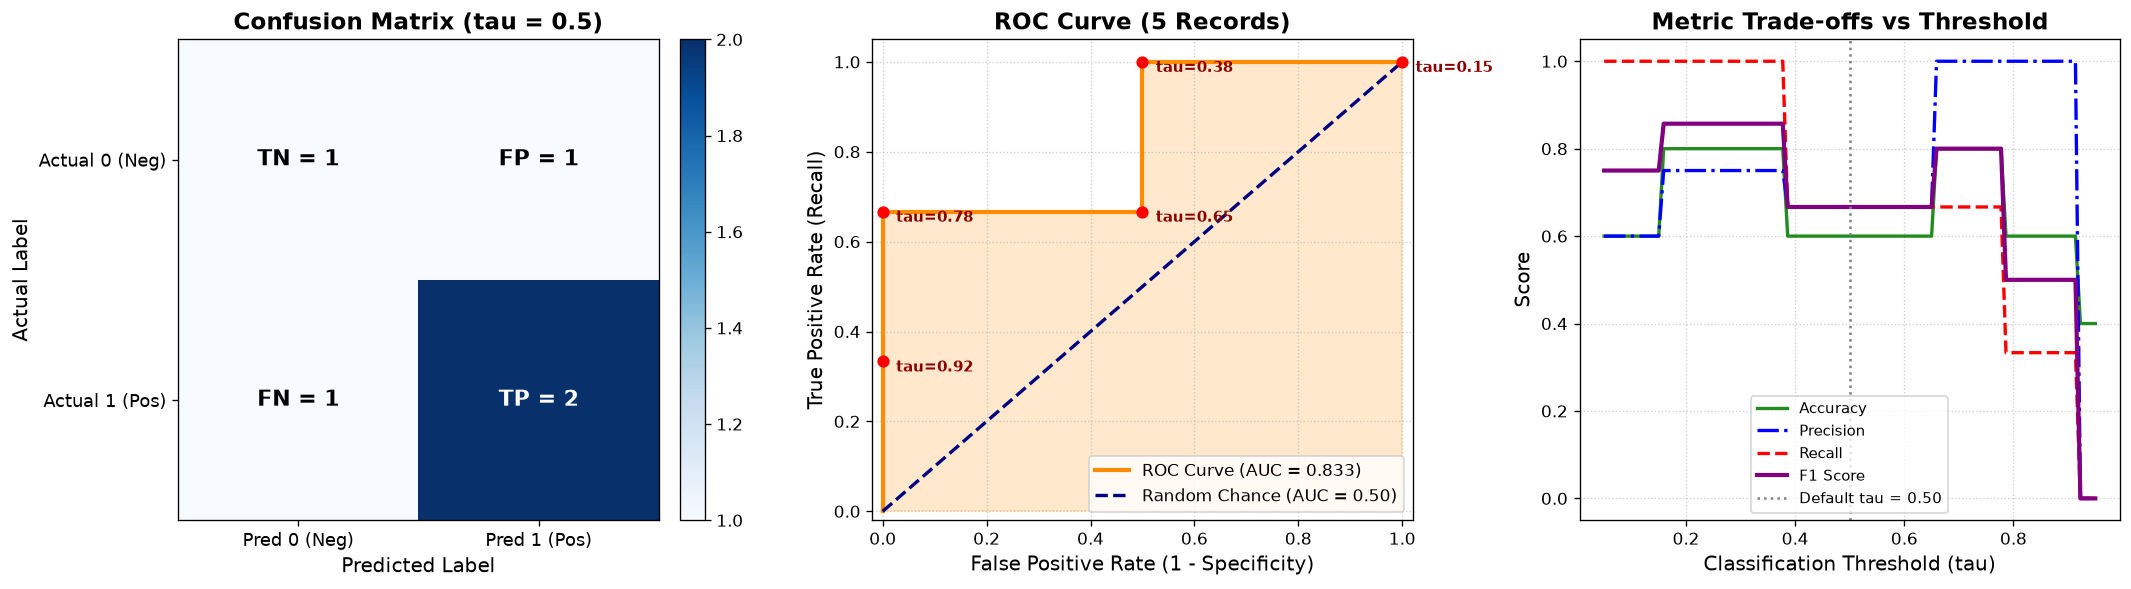

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Confusion Matrix Heatmap
im = axes[0].imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
axes[0].set_title(f"Confusion Matrix (tau = {threshold})", fontsize=14, fontweight='bold')
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)
tick_marks = np.arange(2)
axes[0].set_xticks(tick_marks)
axes[0].set_xticklabels(['Pred 0 (Neg)', 'Pred 1 (Pos)'], fontsize=11)
axes[0].set_yticks(tick_marks)
axes[0].set_yticklabels(['Actual 0 (Neg)', 'Actual 1 (Pos)'], fontsize=11)
axes[0].set_ylabel('Actual Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Annotate cells
cell_text = [[f"TN = {tn}", f"FP = {fp}"], [f"FN = {fn}", f"TP = {tp}"]]
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cell_text[i][j], ha="center", va="center",
                     color="white" if cm[i, j] > (cm.max() / 2.) else "black",
                     fontsize=13, fontweight='bold')

# Plot 2: ROC Curve for 5-Record Dataset
fpr, tpr, roc_thresh = roc_curve(y_true, y_prob)
auc_val = auc(fpr, tpr)

axes[1].step(fpr, tpr, where='post', color='darkorange', lw=2.5, label=f'ROC Curve (AUC = {auc_val:.3f})')
axes[1].fill_between(fpr, tpr, step='post', alpha=0.2, color='darkorange')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chance (AUC = 0.50)')
axes[1].set_xlim([-0.02, 1.02])
axes[1].set_ylim([-0.02, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[1].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[1].set_title('ROC Curve (5 Records)', fontsize=14, fontweight='bold')
axes[1].legend(loc="lower right", fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

# Annotate operating thresholds on ROC curve
for idx, (f, t, th) in enumerate(zip(fpr, tpr, roc_thresh)):
    if np.isneginf(th) or np.isposinf(th):
        continue
    axes[1].scatter(f, t, color='red', s=40, zorder=5)
    axes[1].annotate(f'tau={th:.2f}', (f, t), textcoords="offset points", xytext=(8, -6),
                     fontsize=9, color='darkred', fontweight='semibold')

# Plot 3: Metrics vs Threshold Curve
threshold_range = np.linspace(0.05, 0.95, 100)
accuracies, precisions, recalls, f1s = [], [], [], []

for t_val in threshold_range:
    preds = (y_prob >= t_val).astype(int)
    accuracies.append(accuracy_score(y_true, preds))
    recalls.append(recall_score(y_true, preds, zero_division=0))
    precisions.append(precision_score(y_true, preds, zero_division=0))
    f1s.append(f1_score(y_true, preds, zero_division=0))

axes[2].plot(threshold_range, accuracies, label='Accuracy', lw=2, color='forestgreen')
axes[2].plot(threshold_range, precisions, label='Precision', lw=2, color='blue', linestyle='-.')
axes[2].plot(threshold_range, recalls, label='Recall', lw=2, color='red', linestyle='--')
axes[2].plot(threshold_range, f1s, label='F1 Score', lw=2.5, color='purple')
axes[2].axvline(0.50, color='gray', linestyle=':', label='Default tau = 0.50')
axes[2].set_xlabel('Classification Threshold (tau)', fontsize=12)
axes[2].set_ylabel('Score', fontsize=12)
axes[2].set_title('Metric Trade-offs vs Threshold', fontsize=14, fontweight='bold')
axes[2].legend(loc='lower center', fontsize=9)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


<a name="section_5_3"></a>
### 5.3 Regression Metrics Code & Outlier Sensitivity

Below we implement the 5-point regression dataset using `mean_absolute_error`, `mean_squared_error`, `root_mean_squared_error`, and `r2_score`. We also conduct an empirical sensitivity experiment demonstrating how a single outlier degrades RMSE significantly faster than MAE.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# 1. 5-point regression dataset
y_reg_true = np.array([10.0, 20.0, 15.0, 30.0, 25.0])
y_reg_pred = np.array([12.0, 18.0, 16.0, 32.0, 22.0])

# Detailed tabular breakdown
residuals = y_reg_true - y_reg_pred
abs_errors = np.abs(residuals)
sq_errors = residuals ** 2
y_bar = np.mean(y_reg_true)
tot_errors = (y_reg_true - y_bar) ** 2

df_reg = pd.DataFrame({
    'Point_i': [1, 2, 3, 4, 5],
    'Actual_y': y_reg_true,
    'Predicted_y': y_reg_pred,
    'Residual (e_i)': residuals,
    '|e_i| (Abs Error)': abs_errors,
    'e_i^2 (Sq Error)': sq_errors,
    '(y_i - y_bar)^2': tot_errors
})
print("--- 5-Point Regression Dataset & Step-by-Step Deviations ---")
print(df_reg.to_string(index=False))
print()
print(f"Sum of Absolute Errors (SAE): {abs_errors.sum():.2f}")
print(f"Sum of Squared Errors (SSE/SS_res): {sq_errors.sum():.2f}")
print(f"Total Sum of Squares (SST/SS_tot): {tot_errors.sum():.2f}")
print(f"Mean of Actual y (y_bar): {y_bar:.2f}")

# 2. Compute metrics
mae = mean_absolute_error(y_reg_true, y_reg_pred)
mse = mean_squared_error(y_reg_true, y_reg_pred)
rmse = root_mean_squared_error(y_reg_true, y_reg_pred)
r2 = r2_score(y_reg_true, y_reg_pred)

print()
print("--- Computed Regression Metrics ---")
print(f"Mean Absolute Error (MAE):       {mae:.4f}  (Manual: 10.0 / 5 = 2.0)")
print(f"Mean Squared Error (MSE):        {mse:.4f}  (Manual: 22.0 / 5 = 4.4)")
print(f"Root Mean Squared Error (RMSE):  {rmse:.4f}  (Manual: sqrt(4.4) ≈ 2.0976)")
print(f"R-squared (R^2 Score):           {r2:.4f}  (Manual: 1 - 22.0/250.0 = 0.9120)")

# 3. Sensitivity to Outliers Experiment
print()
print("--- Outlier Sensitivity Demonstration ---")
# Introduce a single large error at point 5 (predict 45 instead of 22)
y_pred_outlier = np.array([12.0, 18.0, 16.0, 32.0, 45.0])
mae_outlier = mean_absolute_error(y_reg_true, y_pred_outlier)
rmse_outlier = root_mean_squared_error(y_reg_true, y_pred_outlier)
r2_outlier = r2_score(y_reg_true, y_pred_outlier)

print(f"Original Clean Data  -> MAE: {mae:.2f}, RMSE: {rmse:.2f}, R^2: {r2:.4f}")
print(f"With Single Outlier  -> MAE: {mae_outlier:.2f} (+{mae_outlier - mae:.2f}), "
      f"RMSE: {rmse_outlier:.2f} (+{rmse_outlier - rmse:.2f}), R^2: {r2_outlier:.4f}")


--- 5-Point Regression Dataset & Step-by-Step Deviations ---
 Point_i  Actual_y  Predicted_y  Residual (e_i)  |e_i| (Abs Error)  e_i^2 (Sq Error)  (y_i - y_bar)^2
       1      10.0         12.0            -2.0                2.0               4.0            100.0
       2      20.0         18.0             2.0                2.0               4.0              0.0
       3      15.0         16.0            -1.0                1.0               1.0             25.0
       4      30.0         32.0            -2.0                2.0               4.0            100.0
       5      25.0         22.0             3.0                3.0               9.0             25.0

Sum of Absolute Errors (SAE): 10.00
Sum of Squared Errors (SSE/SS_res): 22.00
Total Sum of Squares (SST/SS_tot): 250.00
Mean of Actual y (y_bar): 20.00

--- Computed Regression Metrics ---
Mean Absolute Error (MAE):       2.0000  (Manual: 10.0 / 5 = 2.0)
Mean Squared Error (MSE):        4.4000  (Manual: 22.0 / 5 = 4.4)
Root 

<a name="section_5_4"></a>
### 5.4 Regression Visualizations: Actual vs. Fitted and Residuals

Below we plot the Actual vs. Predicted values with vertical residual lines, the Residual vs. Fitted plot, and a sensitivity comparison curve tracking MAE vs. RMSE as an outlier's error magnitude grows.


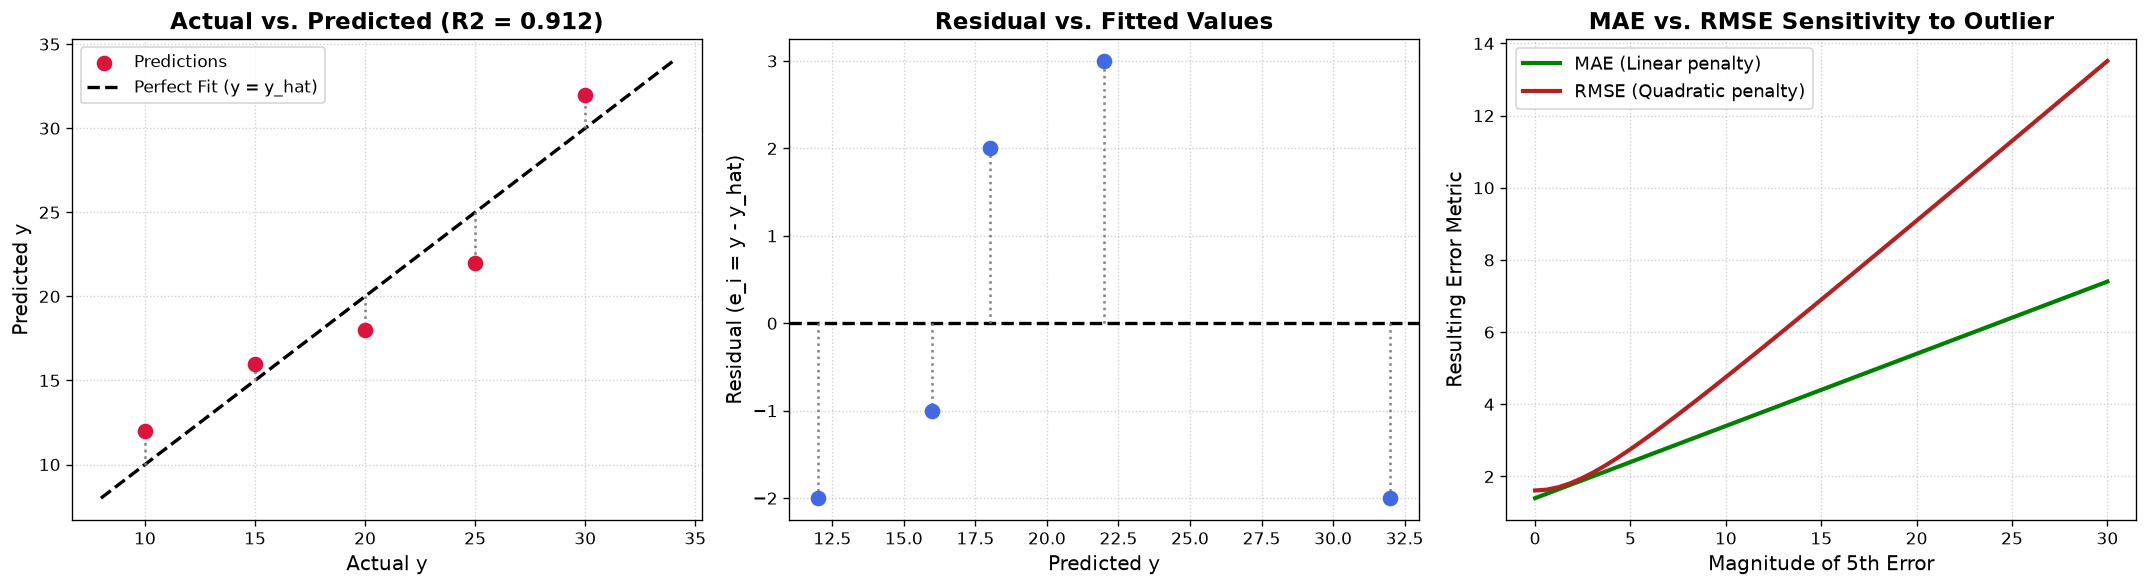

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Actual vs Predicted with Residuals
axes[0].scatter(y_reg_true, y_reg_pred, color='crimson', s=70, zorder=5, label='Predictions')
min_val = min(y_reg_true.min(), y_reg_pred.min()) - 2
max_val = max(y_reg_true.max(), y_reg_pred.max()) + 2
axes[0].plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, label='Perfect Fit (y = y_hat)')

# Draw vertical lines for residuals
for actual, pred in zip(y_reg_true, y_reg_pred):
    axes[0].plot([actual, actual], [actual, pred], color='gray', linestyle=':', lw=1.5)

axes[0].set_xlabel('Actual y', fontsize=12)
axes[0].set_ylabel('Predicted y', fontsize=12)
axes[0].set_title(f'Actual vs. Predicted (R2 = {r2:.3f})', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Residual Plot (e_i vs y_pred)
axes[1].scatter(y_reg_pred, residuals, color='royalblue', s=70, zorder=5)
axes[1].axhline(0, color='black', linestyle='--', lw=2)
for pred, res in zip(y_reg_pred, residuals):
    axes[1].plot([pred, pred], [0, res], color='gray', linestyle=':', lw=1.5)

axes[1].set_xlabel('Predicted y', fontsize=12)
axes[1].set_ylabel('Residual (e_i = y - y_hat)', fontsize=12)
axes[1].set_title('Residual vs. Fitted Values', fontsize=14, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Plot 3: Outlier Error Sensitivity Comparison
error_magnitudes = np.linspace(0, 30, 50)
maes, rmses = [], []
base_errors = np.array([2.0, -2.0, 1.0, 2.0])  # first 4 errors

for err in error_magnitudes:
    all_errs = np.append(base_errors, err)
    maes.append(np.mean(np.abs(all_errs)))
    rmses.append(np.sqrt(np.mean(all_errs ** 2)))

axes[2].plot(error_magnitudes, maes, label='MAE (Linear penalty)', lw=2.5, color='green')
axes[2].plot(error_magnitudes, rmses, label='RMSE (Quadratic penalty)', lw=2.5, color='firebrick')
axes[2].set_xlabel('Magnitude of 5th Error', fontsize=12)
axes[2].set_ylabel('Resulting Error Metric', fontsize=12)
axes[2].set_title('MAE vs. RMSE Sensitivity to Outlier', fontsize=14, fontweight='bold')
axes[2].legend(fontsize=11)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


<a name="section_5_5"></a>
### 5.5 Clustering Metrics Code (Toy Dataset Verification)

Below we verify the 4-point toy clustering calculations using Scikit-Learn's `silhouette_samples`, `silhouette_score`, `davies_bouldin_score`, and `calinski_harabasz_score`.


In [ ]:
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score

# 1. 4-point toy clustering dataset
X_toy = np.array([[1.0], [2.0], [6.0], [8.0]])
labels_toy = np.array([0, 0, 1, 1])

# 2. Compute metrics
s_samples = silhouette_samples(X_toy, labels_toy)
s_score = silhouette_score(X_toy, labels_toy)
db_score = davies_bouldin_score(X_toy, labels_toy)
ch_score = calinski_harabasz_score(X_toy, labels_toy)

# Calculate inertia manually
c0_mean = np.mean(X_toy[labels_toy == 0])
c1_mean = np.mean(X_toy[labels_toy == 1])
inertia_manual = np.sum((X_toy[labels_toy == 0] - c0_mean)**2) + np.sum((X_toy[labels_toy == 1] - c1_mean)**2)

print("--- 4-Point Toy Clustering Metrics Verification ---")
print(f"Point 1 (x=1): s(x_1) = {s_samples[0]:.4f} (Manual: 5/6 ≈ 0.8333)")
print(f"Point 2 (x=2): s(x_2) = {s_samples[1]:.4f} (Manual: 4/5 = 0.8000)")
print(f"Point 3 (x=6): s(x_3) = {s_samples[2]:.4f} (Manual: 5/9 ≈ 0.5556)")
print(f"Point 4 (x=8): s(x_4) = {s_samples[3]:.4f} (Manual: 9/13 ≈ 0.6923)")
print("--------------------------------------------------")
print(f"Average Silhouette Score:      {s_score:.4f}  (Manual: 0.7203)")
print(f"Davies-Bouldin Index (DBI):    {db_score:.4f}  (Manual: 3/11 ≈ 0.2727)")
print(f"Calinski-Harabasz Score (CH):  {ch_score:.4f}  (Manual: 24.2000)")
print(f"Within-Cluster Inertia (WCSS): {inertia_manual:.4f}  (Manual: 2.5000)")


--- 4-Point Toy Clustering Metrics Verification ---
Point 1 (x=1): s(x_1) = 0.8333 (Manual: 5/6 ≈ 0.8333)
Point 2 (x=2): s(x_2) = 0.8000 (Manual: 4/5 = 0.8000)
Point 3 (x=6): s(x_3) = 0.5556 (Manual: 5/9 ≈ 0.5556)
Point 4 (x=8): s(x_4) = 0.6923 (Manual: 9/13 ≈ 0.6923)
--------------------------------------------------
Average Silhouette Score:      0.7203  (Manual: 0.7203)
Davies-Bouldin Index (DBI):    0.2727  (Manual: 3/11 ≈ 0.2727)
Calinski-Harabasz Score (CH):  24.2000  (Manual: 24.2000)
Within-Cluster Inertia (WCSS): 2.5000  (Manual: 2.5000)


<a name="section_5_6"></a>
### 5.6 Realistic Clustering Experiment: K-Means Multi-Metric Analysis

In real-world data science workflows, you rarely know $K$ in advance. Below, we generate a synthetic 2D dataset with $4$ ground-truth Gaussian clusters and systematically sweep $K \in [2, 7]$. We simultaneously plot the **Elbow Curve (Inertia)**, **Silhouette Score**, **Davies-Bouldin Index**, and the resulting optimal cluster partition.


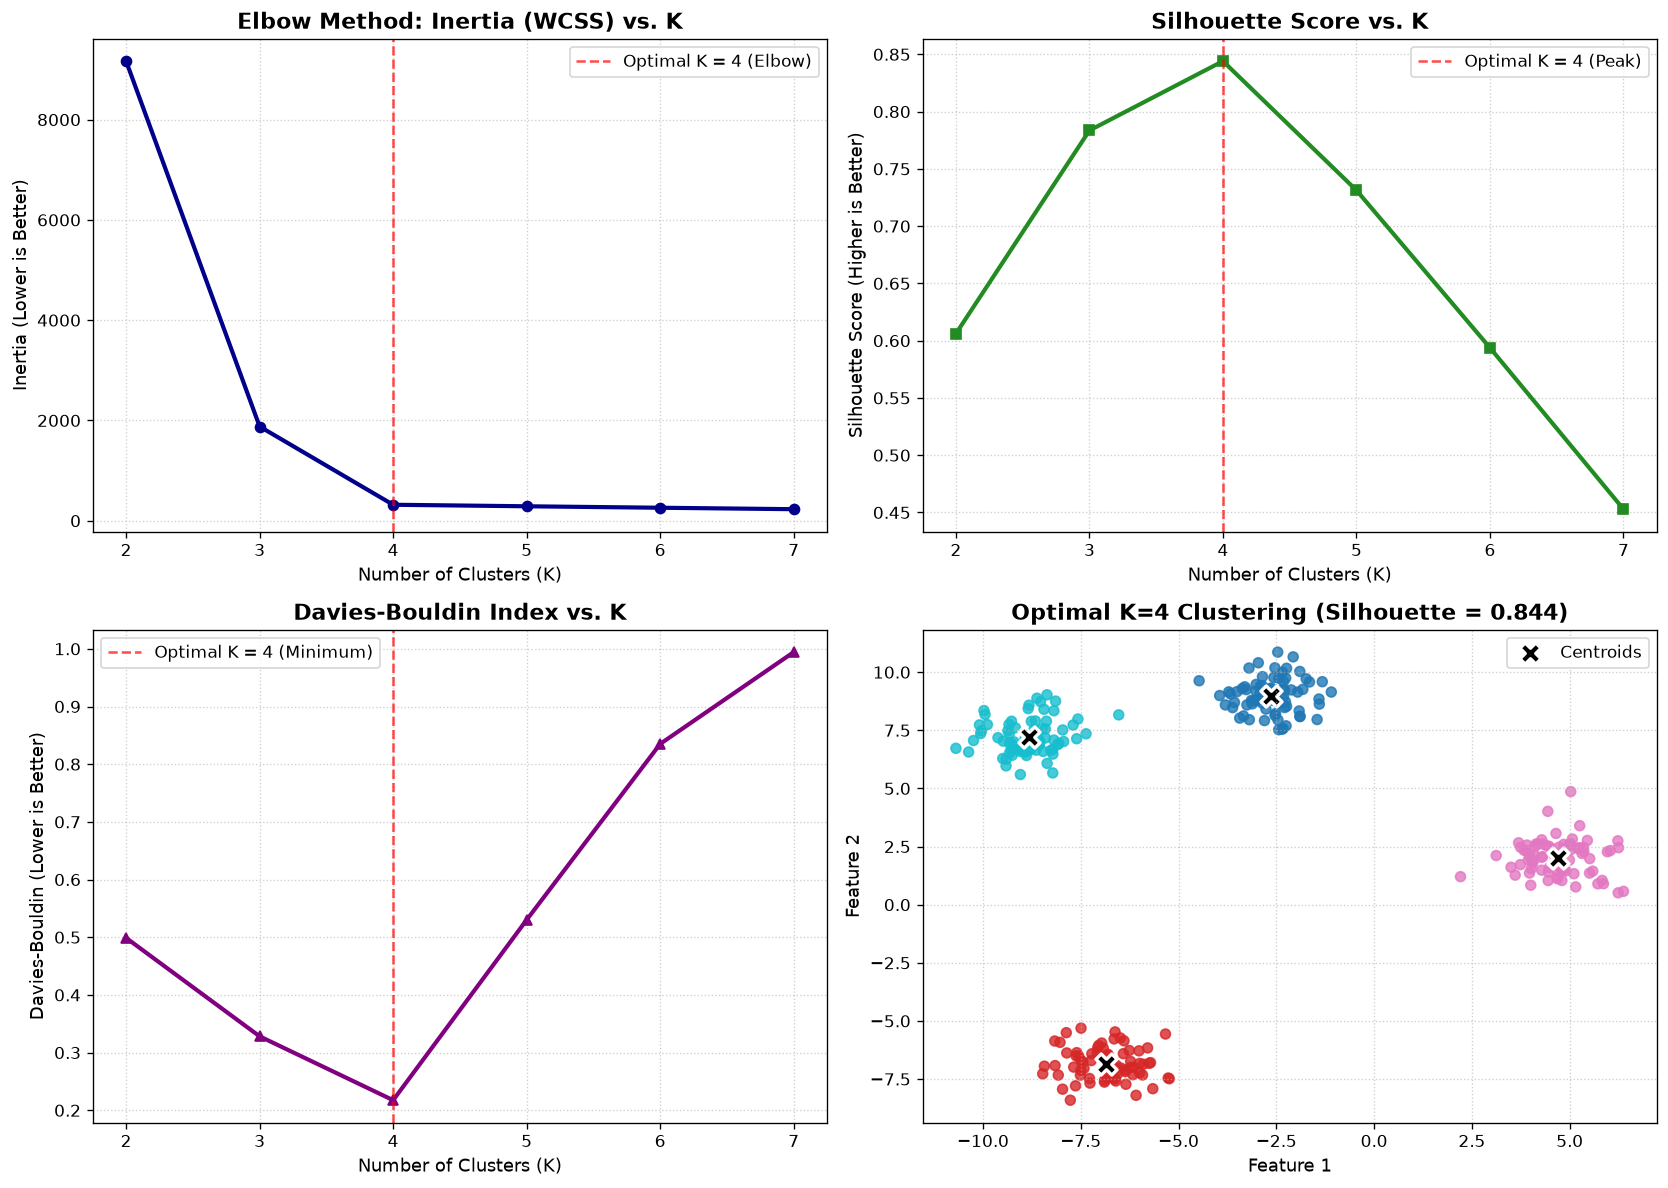

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate realistic 2D clustered dataset (4 ground-truth clusters)
np.random.seed(42)
X_blobs, y_blobs = make_blobs(n_samples=300, centers=4, cluster_std=0.75, random_state=42)

# 2. Evaluate K from 2 to 7 across all four clustering metrics
k_range = list(range(2, 8))
inertias, sil_scores, dbi_scores, ch_scores = [], [], [], []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_blobs)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_blobs, cluster_labels))
    dbi_scores.append(davies_bouldin_score(X_blobs, cluster_labels))
    ch_scores.append(calinski_harabasz_score(X_blobs, cluster_labels))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Elbow Method (Inertia vs K)
axes[0, 0].plot(k_range, inertias, marker='o', lw=2.5, color='darkblue')
axes[0, 0].axvline(4, color='red', linestyle='--', alpha=0.7, label='Optimal K = 4 (Elbow)')
axes[0, 0].set_title('Elbow Method: Inertia (WCSS) vs. K', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[0, 0].set_ylabel('Inertia (Lower is Better)', fontsize=11)
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Silhouette Score vs K
axes[0, 1].plot(k_range, sil_scores, marker='s', lw=2.5, color='forestgreen')
axes[0, 1].axvline(4, color='red', linestyle='--', alpha=0.7, label='Optimal K = 4 (Peak)')
axes[0, 1].set_title('Silhouette Score vs. K', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[0, 1].set_ylabel('Silhouette Score (Higher is Better)', fontsize=11)
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Plot 3: Davies-Bouldin Index vs K
axes[1, 0].plot(k_range, dbi_scores, marker='^', lw=2.5, color='purple')
axes[1, 0].axvline(4, color='red', linestyle='--', alpha=0.7, label='Optimal K = 4 (Minimum)')
axes[1, 0].set_title('Davies-Bouldin Index vs. K', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Number of Clusters (K)', fontsize=11)
axes[1, 0].set_ylabel('Davies-Bouldin (Lower is Better)', fontsize=11)
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Plot 4: Optimal Clustering Visualized (K=4)
optimal_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
optimal_labels = optimal_kmeans.fit_predict(X_blobs)
scatter = axes[1, 1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=optimal_labels, cmap='tab10', s=35, alpha=0.8)
centers = optimal_kmeans.cluster_centers_
axes[1, 1].scatter(centers[:, 0], centers[:, 1], marker='X', c='black', s=160, edgecolor='white', lw=2, label='Centroids')
axes[1, 1].set_title(f'Optimal K=4 Clustering (Silhouette = {sil_scores[2]:.3f})', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Feature 1', fontsize=11)
axes[1, 1].set_ylabel('Feature 2', fontsize=11)
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


<a name="part_6"></a>
# Part 6: Master Summary & Decision Cheat Sheet

To conclude, here is a consolidated quick-reference matrix across all three machine learning paradigms:

| Paradigm | Metric | Primary Purpose | Goal | Vulnerability / Watch Out |
|:---|:---|:---|:---:|:---|
| **Classification** | **Accuracy** | Overall hit rate | Higher | Flawed under class imbalance (**Accuracy Paradox**) |
| | **Precision** | Confidence when predicting positive | Higher | Ignores missed positive cases ($FN$) |
| | **Recall (Sensitivity)** | Coverage of actual positive cases | Higher | Ignores false alarms ($FP$) |
| | **F1 Score** | Harmonic compromise of Precision & Recall | Higher | Equal weighting may not match business costs |
| | **ROC-AUC** | Threshold-independent ranking power | Higher | Can appear optimistic if negatives heavily outnumber positives |
| **Regression** | **MAE** | Median error magnitude (robust) | Lower | Does not heavily penalize rare large errors |
| | **RMSE** | Mean error magnitude (penalizes outliers) | Lower | Highly sensitive to extreme anomalies |
| | **$R^2$ Score** | Proportion of target variance explained | Higher | Can be negative on test data if fit is worse than mean baseline |
| | **Adjusted $R^2$** | Model fit adjusted for number of predictors | Higher | Decreases if added features lack predictive power |
| **Clustering** | **Inertia (WCSS)** | Intra-cluster compactness | Lower | Monotonically decreases with $K$; requires elbow method |
| | **Silhouette Score** | Balance of cohesion vs. separation | Higher | Computationally expensive ($O(n^2)$); favors spherical clusters |
| | **Davies-Bouldin** | Ratio of cluster scatter to centroid separation | Lower | Tends to favor spherical clusters; sensitive to density variations |
| | **Calinski-Harabasz** | Ratio of between-cluster to within-cluster variance | Higher | Fast to compute; tends to favor convex/spherical clusters |

---

<a name="copyright_section"></a>
### Copyright Notice
© 2026 Ghassem Tofighi. All rights reserved. Unauthorized reuse or distribution is prohibited.
